In [1]:
!pip install pandas
!pip install matplotlib

In [2]:
#IMPORT LIBRARIES 

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib
from imblearn.over_sampling import SMOTE

In [3]:
#LOAD DATASET 

data = pd.read_csv("credit_card_fraud_dataset.csv")

print(data.head())

print(data.shape)

print(data.columns)

   TransactionID             TransactionDate   Amount  MerchantID  \
0              1  2024-04-03 14:15:35.462794  4189.27         688   
1              2  2024-03-19 13:20:35.462824  2659.71         109   
2              3  2024-01-08 10:08:35.462834   784.00         394   
3              4  2024-04-13 23:50:35.462850  3514.40         944   
4              5  2024-07-12 18:51:35.462858   369.07         475   

  TransactionType      Location  IsFraud  
0          refund   San Antonio        0  
1          refund        Dallas        0  
2        purchase      New York        0  
3        purchase  Philadelphia        0  
4        purchase       Phoenix        0  
(100000, 7)
Index(['TransactionID', 'TransactionDate', 'Amount', 'MerchantID',
       'TransactionType', 'Location', 'IsFraud'],
      dtype='object')


In [4]:
#EXPLORE DATA (EDA)

print(data.info())

print(data.describe())

print(data.isnull().sum())

print(data["IsFraud"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 7 columns):
 #   Column           Non-Null Count   Dtype  
---  ------           --------------   -----  
 0   TransactionID    100000 non-null  int64  
 1   TransactionDate  100000 non-null  object 
 2   Amount           100000 non-null  float64
 3   MerchantID       100000 non-null  int64  
 4   TransactionType  100000 non-null  object 
 5   Location         100000 non-null  object 
 6   IsFraud          100000 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 5.3+ MB
None
       TransactionID         Amount     MerchantID        IsFraud
count  100000.000000  100000.000000  100000.000000  100000.000000
mean    50000.500000    2497.092666     501.676070       0.010000
std     28867.657797    1442.415999     288.715868       0.099499
min         1.000000       1.050000       1.000000       0.000000
25%     25000.750000    1247.955000     252.000000       0.000000
50%  

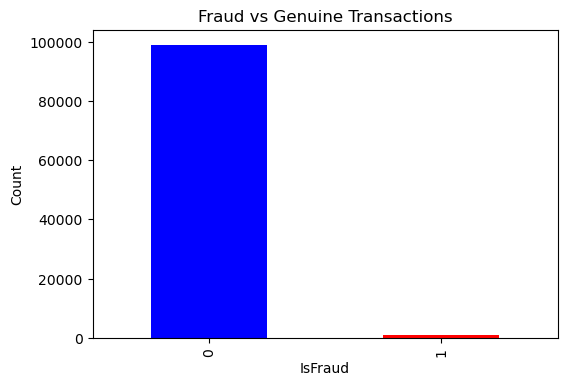

In [5]:
#VISUALIZATION

data["IsFraud"].value_counts().plot(kind="bar", color=["blue","red"],figsize=(6,4))

plt.title("Fraud vs Genuine Transactions")
plt.xlabel("IsFraud")
plt.ylabel("Count")
plt.show()

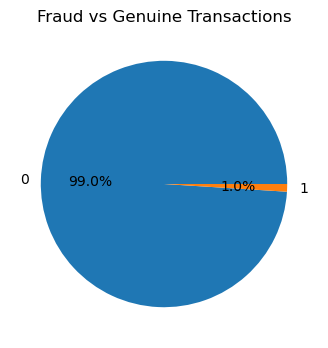

In [6]:
import matplotlib.pyplot as plt

data["IsFraud"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(4,4)
)

plt.title("Fraud vs Genuine Transactions")
plt.ylabel("")
plt.show()

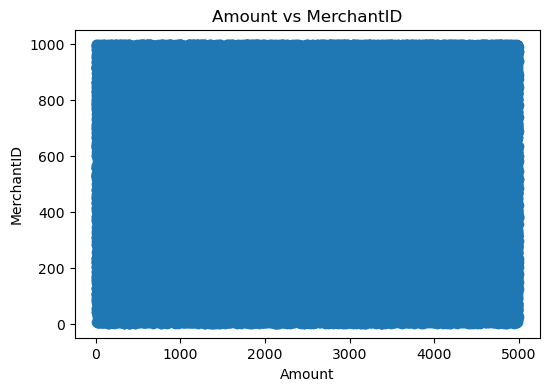

In [7]:
plt.figure(figsize=(6,4))

plt.scatter(data["Amount"], data["MerchantID"])

plt.xlabel("Amount")
plt.ylabel("MerchantID")
plt.title("Amount vs MerchantID")

plt.show()

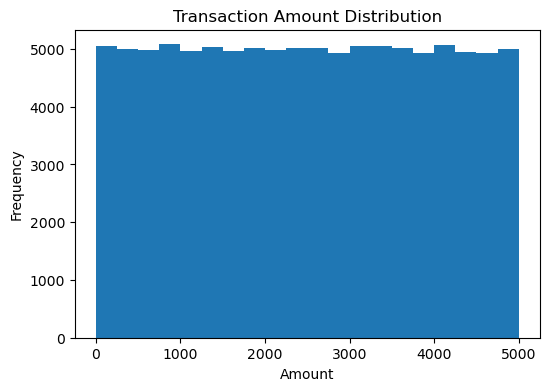

In [8]:
plt.figure(figsize=(6,4))

plt.hist(data["Amount"], bins=20)

plt.xlabel("Amount")
plt.ylabel("Frequency")
plt.title("Transaction Amount Distribution")

plt.show()

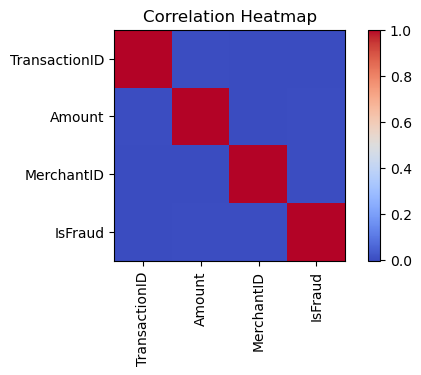

In [9]:
plt.figure(figsize=(6,3))
correlation = data.select_dtypes(include="number").corr()

plt.imshow(correlation, cmap="coolwarm")
plt.colorbar()
plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Correlation Heatmap")

plt.show()

In [10]:
#DATA CLEANING

print("Duplicate Rows:", data.duplicated().sum())

data = data.drop_duplicates()

data = data.dropna()

Duplicate Rows: 0


In [11]:
#FEATURE ENGINEERING

# Convert TransactionDate only if it exists
if "TransactionDate" in data.columns:
    data["TransactionDate"] = pd.to_datetime(data["TransactionDate"])

    data["Year"] = data["TransactionDate"].dt.year
    data["Month"] = data["TransactionDate"].dt.month
    data["Day"] = data["TransactionDate"].dt.day

    data.drop("TransactionDate", axis=1, inplace=True)

#ENCODE TEXT COLUMN 
le = LabelEncoder()

if "TransactionType" in data.columns:
    data["TransactionType"] = le.fit_transform(data["TransactionType"])

if "Location" in data.columns:
    data["Location"] = le.fit_transform(data["Location"])

print(data.head())

   TransactionID   Amount  MerchantID  TransactionType  Location  IsFraud  \
0              1  4189.27         688                1         7        0   
1              2  2659.71         109                1         1        0   
2              3   784.00         394                0         4        0   
3              4  3514.40         944                0         5        0   
4              5   369.07         475                0         6        0   

   Year  Month  Day  
0  2024      4    3  
1  2024      3   19  
2  2024      1    8  
3  2024      4   13  
4  2024      7   12  


In [17]:
#FEATURE SELECTION

X = data.drop("IsFraud", axis=1)
y = data["IsFraud"]

In [16]:
#TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
X,
y,
test_size=0.20,
random_state=42
)

In [28]:
smote=SMOTE(random_state=42)
X_train_smote,y_train_smote=smote.fit_resample(X_train,y_train)
print(y_train_smote.value_counts())
model.fit(X_train_smote,y_train_smote)
grid.fit(X_train_smote,y_train_smote)

IsFraud
0    79213
1    79213
Name: count, dtype: int64


,estimator,LogisticRegre...max_iter=1000)
,param_grid,"{'C': [0.1, 1, ...], 'solver': ['lbfgs']}"
,scoring,None
,n_jobs,None
,refit,True
,cv,3
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [18]:
print(X_train.dtypes)

TransactionID        int64
Amount             float64
MerchantID           int64
TransactionType      int64
Location             int64
Year                 int32
Month                int32
Day                  int32
dtype: object


In [19]:
print(X_train.select_dtypes(include=['object']).columns)

Index([], dtype='object')


In [20]:
# Feature Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature Scaling Completed Successfully!")

Feature Scaling Completed Successfully!


In [21]:
#TRAIN MODEL

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [22]:
#MODEL EVALUTION

prediction = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, prediction))
print(confusion_matrix(y_test, prediction))
print(classification_report(y_test, prediction, zero_division=0))

Accuracy: 0.98935
[[19787     0]
 [  213     0]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     19787
           1       0.00      0.00      0.00       213

    accuracy                           0.99     20000
   macro avg       0.49      0.50      0.50     20000
weighted avg       0.98      0.99      0.98     20000



In [23]:
train_acc = model.score(X_train, y_train)
test_acc = model.score(X_test, y_test)

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)

Training Accuracy: 0.9901625
Testing Accuracy: 0.98935


In [24]:
#HYPERPARAMETER TUNING

parameters = {

"C":[0.1,1,10],
"solver":["lbfgs"]
}

grid = GridSearchCV(
model,
parameters,
cv=3
)

grid.fit(X_train, y_train)

print(grid.best_params_)

{'C': 0.1, 'solver': 'lbfgs'}


In [25]:
#SAVE MODEL

joblib.dump(grid.best_estimator_,"Fraud_Model.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [26]:
#PREDICTION

sample = X_test[0].reshape(1, -1)

result = grid.predict(sample)

if result[0] == 1:
    print("Fraud Transaction")
else:
    print("Genuine Transaction")

Genuine Transaction
